In [1]:
import os, sys

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)


In [2]:
import sift_config as cfg
from SIFT.sift_utils import *
from core.process_dataset import *
from core.evaluations import *


# Load Dataset

In [3]:
train_images, train_labels, test_images, test_labels, classes = sift_split_data(
    data_root=cfg.DATA_ROOT,
    test_ratio=cfg.TEST_SIZE,
    sample_ratio=cfg.SAMPLE_RATIO,
    shuffle_seed=cfg.RANDOM_STATE,
    load_color_images=True
)
score_dict = {}

Total: 9600 training images, 2400 testing images


# SIFT+KNN

## Score

In [4]:
clf_type = "knn"
if LOAD_MODEL and os.path.exists(CLASSIFIER_PATH):
    kmeans, scaler, clf = load_sift_model(clf_type)
else:
    kmeans, scaler, clf = train_sift_model(train_images, train_labels, classifier_type=clf_type)
print("  KNN Test Results: ")
y_test_knn, y_pred_knn, classes_knn = test_sift_model(test_images, test_labels, kmeans, scaler, clf, classes)
acc_knn, f1_knn = get_model_score( y_test_knn, y_pred_knn, classes_knn)
score_dict["KNN"] = (acc_knn,f1_knn)

Extract SIFT features from training set...


  The model has been saved as classifier_knn.pkl
  KNN Test Results: 
  Extracting SIFT features from the test set...

Model evaluation results: 
Accuracy: 0.5563
Precision: 0.5901
Recall: 0.5563
F1-score: 0.5432


## Confusion Matrix and Report


Confusion Matrix: 
[[ 94  11   2   8   0   2   0   7   1   3   4   1   8  14   5]
 [  4  88   1  15   0   1   0  16   2   1   0   1  25   4   2]
 [ 13   4  57  16   1   6   1  13  18   4   2   2   5   7  11]
 [  0  12   0 130   0   0   0   0   1   0   0   1  10   6   0]
 [ 13   6   5   2  67   5   7   6   4  22   6   0   1   7   9]
 [  0   1   1   0   3 143   6   2   1   1   0   0   0   1   1]
 [  8   5   4   1  22  23  49  14  13   2   4   0   1  10   4]
 [  2   8   0   3   0   6   0  94   3   1   1   0  26  12   4]
 [ 14   9   4  13   3   6   1  24  37  13   1   2   2  20  11]
 [  2   4   2   3   5   1   0   2  14 112   0   0   1   5   9]
 [  1  14   1   3   1   0   0   8   2   0 116   1   6   6   1]
 [  1  27   0  45   0   0   0   2   3   0   0  52  26   0   4]
 [  0  13   0  10   0   0   0  12   0   2   0   1 121   1   0]
 [  2   8   0  14   0   0   0   3   1   1   0   1   2 128   0]
 [  7  18   3  21   3   1   0  10  13  16   1   1  10   9  47]]

Classification Report: 
         

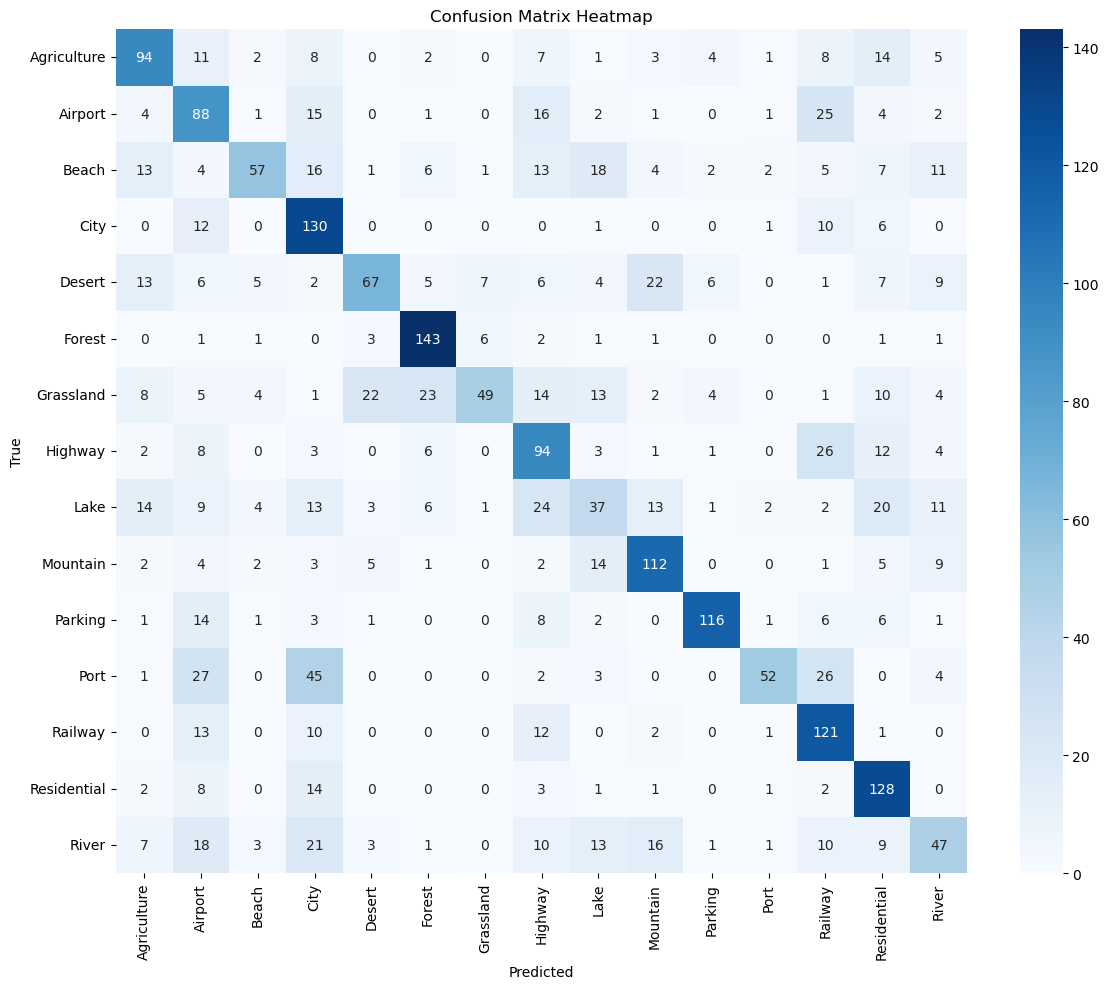

In [5]:
get_model_cm(y_test_knn, y_pred_knn, classes_knn)

# SIFT+SVM

## Score

In [6]:
cfg.CLASSIFIER_TYPE = "svm"
if LOAD_MODEL and os.path.exists(CLASSIFIER_PATH):
    kmeans, scaler, clf = load_sift_model()
else:
    kmeans, scaler, clf = train_sift_model(train_images, train_labels)
print("  SVM Test Results: ")

y_test_svm, y_pred_svm, classes = test_sift_model(test_images, test_labels, kmeans, scaler, clf, classes)
acc_svm, f1_svm = get_model_score( y_test_svm, y_pred_svm, classes)
score_dict["SVM"] = (acc_svm, f1_svm)

  Load cached training features...


  The model has been saved as classifier_svm.pkl
  SVM Test Results: 
  Loading cached test features...

Model evaluation results: 
Accuracy: 0.6754
Precision: 0.6740
Recall: 0.6754
F1-score: 0.6717


## Confusion Matrix and Report


Confusion Matrix: 
[[111   1   0   1   7   1   9   3   7   4   1   1   2   5   7]
 [  9  98   1  11   0   0   0   8   4   0   1   2  13   3  10]
 [  5   2  81   2  13   2  19   5  13   7   1   4   1   2   3]
 [  3   8   1 117   0   0   0   1   2   0   1   7  12   6   2]
 [  0   1   8   0 117   2  13   0   2  12   0   1   0   0   4]
 [  0   0   1   0   1 139  11   1   5   1   0   0   0   1   0]
 [  2   0   3   0  39   7  96   3   5   0   2   0   0   2   1]
 [  1   6   3   3   1   5   0 102   6   0   3   0  19   8   3]
 [ 11   0  17   3   3   5   9  13  60  15   1   1   0   9  13]
 [  0   0   4   1  13   0   1   0   6 127   0   1   1   0   6]
 [  3   5   0   0   1   0   0   3   1   0 138   2   2   4   1]
 [  2  10   1  19   1   0   1   3   4   0   0 105   5   1   8]
 [  0  11   0  13   0   0   0   9   0   0   0   1 120   1   5]
 [  2   4   0   5   1   0   0   1   2   0   1   0   0 143   1]
 [  8  10  10   8   2   0   4   4  18  18   0   4   5   2  67]]

Classification Report: 
         

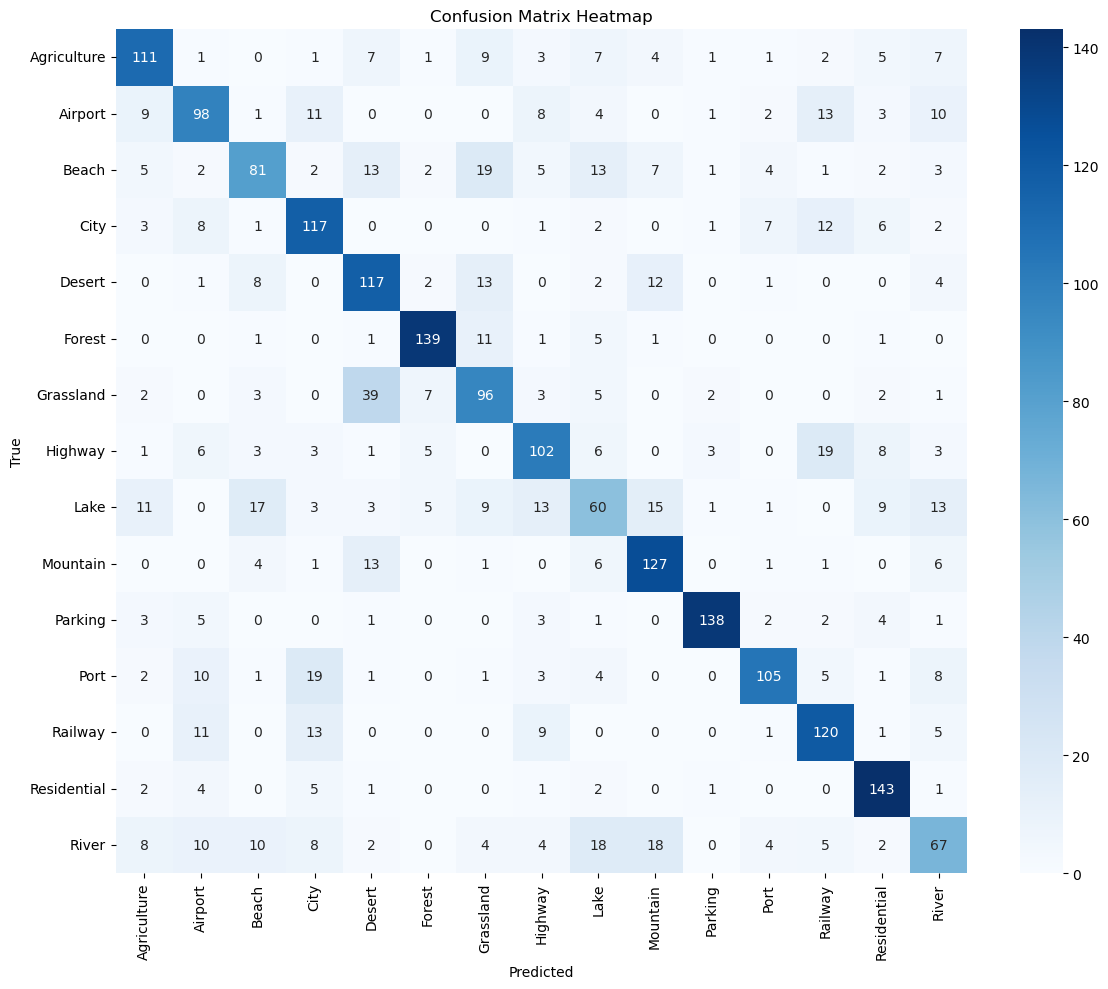

In [7]:
get_model_cm(y_test_svm, y_pred_svm, classes)

# Classifier Comparison

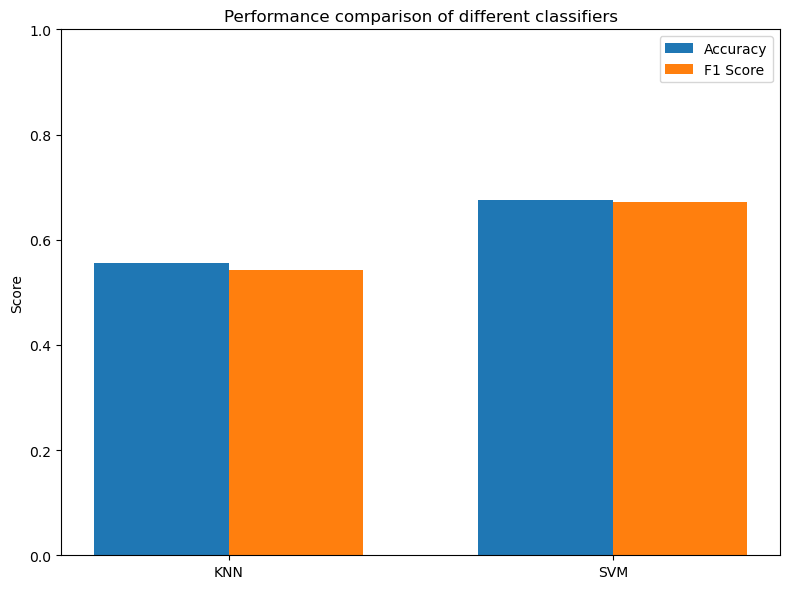

In [8]:
plot_model_comparison(score_dict)

# Robustness Test

## Test for SIFT+SVM

  Model loading completed:classifier_svm.pkl
💥 Testing under perturbation: original


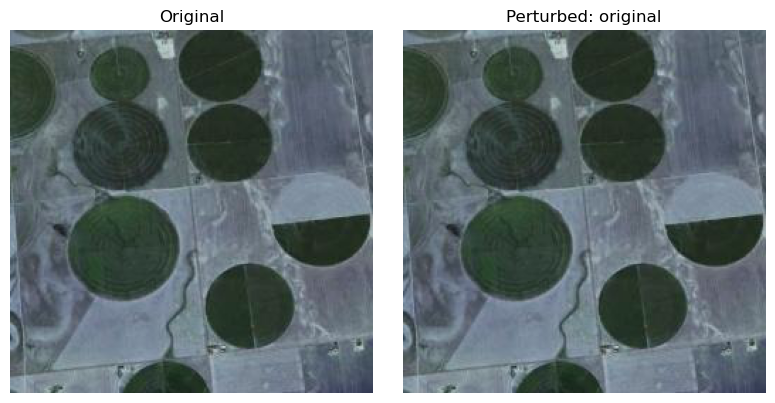

💥 Testing under perturbation: noise


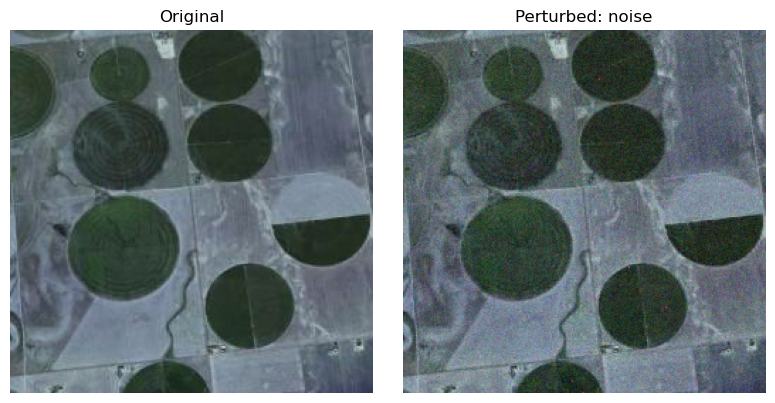

💥 Testing under perturbation: blur


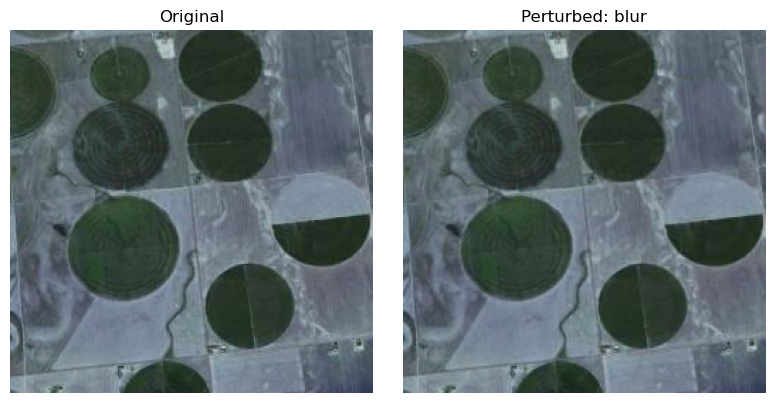

💥 Testing under perturbation: occlusion


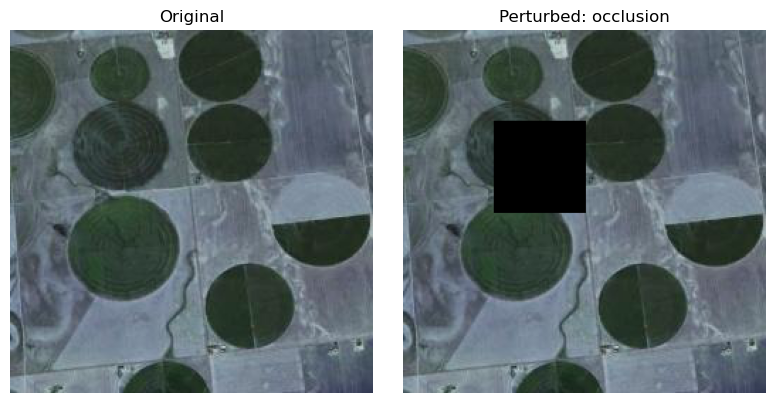

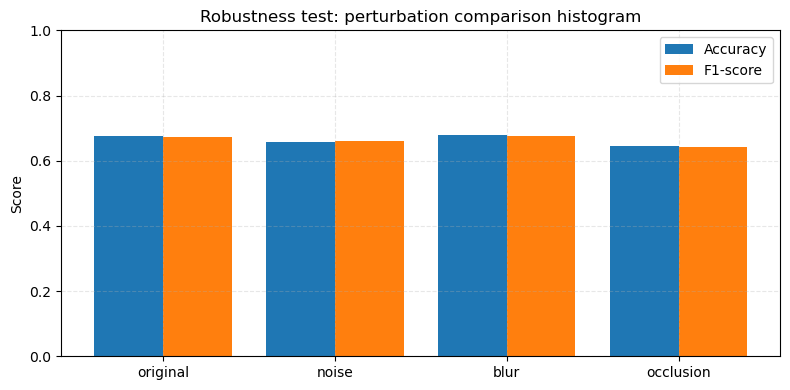

In [9]:
from sift_robustness import *
from sift_utils import apply_perturbation
modes, accs, f1s = test_robustness_with_saved_model(
    test_images, test_labels, classes, classifier_type="svm"
)
plot_robustness_bar_chart(modes, accs, f1s)

## Test for SIFT+KNN

  Model loading completed:classifier_knn.pkl
💥 Testing under perturbation: original


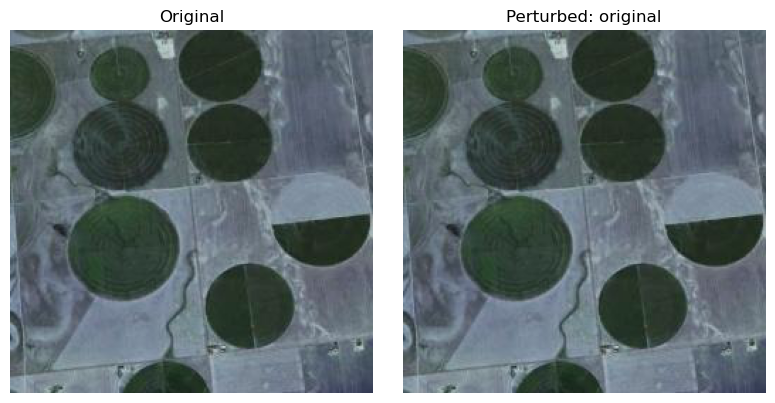

💥 Testing under perturbation: noise


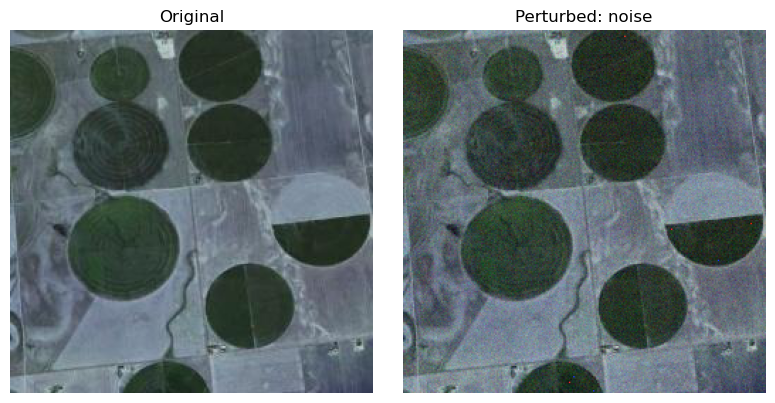

💥 Testing under perturbation: blur


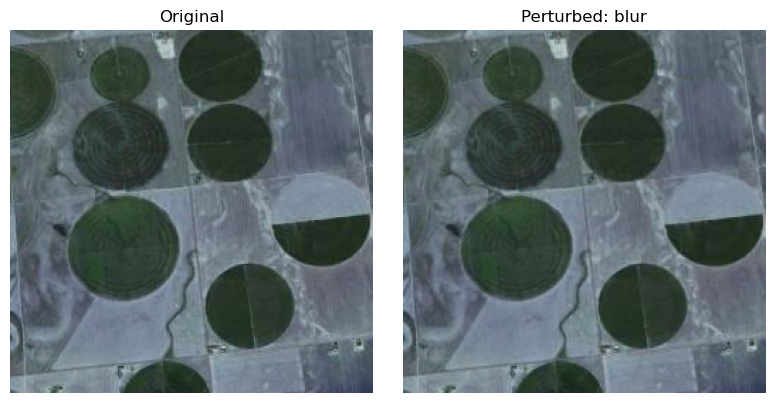

💥 Testing under perturbation: occlusion


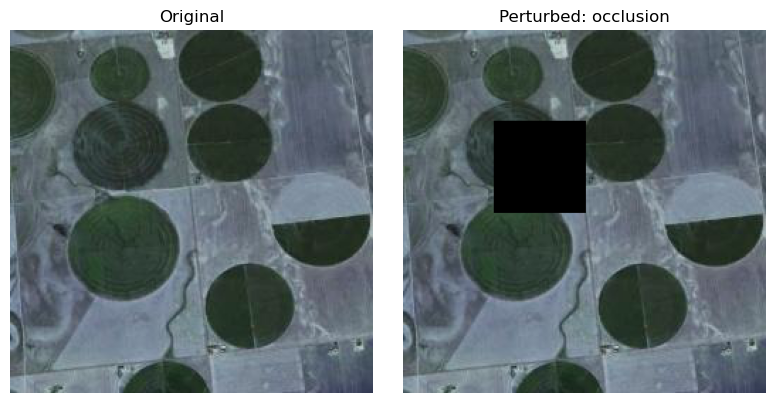

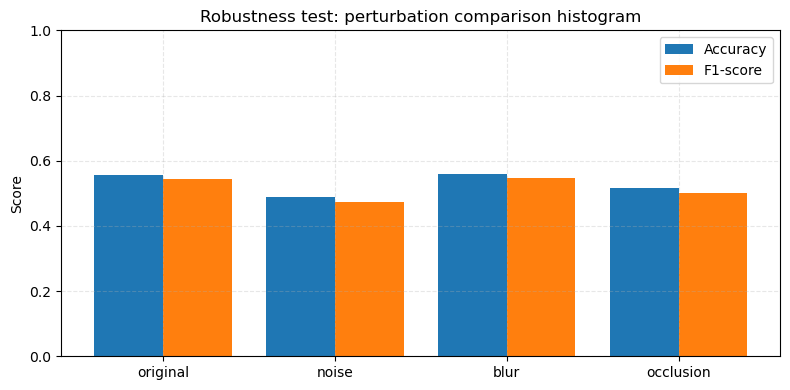

In [10]:
from sift_robustness import *
from sift_utils import apply_perturbation
modes, accs, f1s = test_robustness_with_saved_model(
    test_images, test_labels, classes, classifier_type="knn"
)
plot_robustness_bar_chart(modes, accs, f1s)

# Simulation of Imbalanced Experiment

## Load Dataset(50%)

In [3]:
train_images, train_labels, test_images, test_labels, classes = sift_split_data(
    data_root=cfg.DATA_ROOT,
    test_ratio=cfg.TEST_SIZE,
    sample_ratio=0.5, 
    shuffle_seed=cfg.RANDOM_STATE,
    load_color_images=True
)

Total: 4800 training images, 1200 testing images


## Undersample

In [4]:

imbalance_setting = {
    0: 1.0,  # Agriculture
    1: 1.0,  # Airport
    2: 0.5,  # Beach
    3: 1.0,  # City
    4: 1.0,  # Desert
    5: 1.0,  # Forest
    6: 0.7,  # Grassland 
    7: 1.0,  # Highway 
    8: 0.5,  # Lake
    9: 1.0,  # Mountain
    10: 1.0, # Parking
    11: 1.0, # Port
    12: 1.0, # Railway
    13: 1.0, # Residential
    14: 0.3, # River
}
resampled_images, resampled_labels = simulate_imbalance_and_resample(
    train_images, train_labels,
    imbalance_ratio=imbalance_setting,
    resample_method="undersample", 
    random_state=42
)

kmeans, scaler, clf = train_imbalance_model(resampled_images, resampled_labels, classifier_type="svm")

y_test, y_pred, classes = test_sift_model_imbalance(test_images, test_labels, kmeans, scaler, clf, classes)

acc, f1 = get_model_score(y_test, y_pred, classes)

Extract SIFT features from training set...


  Extract test set SIFT features (without using cache)...

Model evaluation results: 
Accuracy: 0.5925
Precision: 0.5901
Recall: 0.5925
F1-score: 0.5841


## Oversample

In [5]:
imbalance_setting = {
    0: 1.0,  # Agriculture
    1: 1.0,  # Airport
    2: 0.5,  # Beach
    3: 1.0,  # City
    4: 1.0,  # Desert
    5: 1.0,  # Forest
    6: 0.7,  # Grassland 
    7: 1.0,  # Highway 
    8: 0.5,  # Lake
    9: 1.0,  # Mountain
    10: 1.0, # Parking
    11: 1.0, # Port
    12: 1.0, # Railway
    13: 1.0, # Residential
    14: 0.3, # River
}
resampled_images, resampled_labels = simulate_imbalance_and_resample(
    train_images, train_labels,
    imbalance_ratio=imbalance_setting,
    resample_method="oversample",  
    random_state=42
)

kmeans, scaler, clf = train_imbalance_model(resampled_images, resampled_labels, classifier_type="svm")

y_test, y_pred, classes = test_sift_model_imbalance(test_images, test_labels, kmeans, scaler, clf, classes)

acc, f1 = get_model_score(y_test, y_pred, classes)

Extract SIFT features from training set...


  Extract test set SIFT features (without using cache)...

Model evaluation results: 
Accuracy: 0.6167
Precision: 0.6127
Recall: 0.6167
F1-score: 0.6096


# References

Lowe, D. G. (2004). Distinctive image features from scale-invariant keypoints. International journal of computer vision, 60(2), 91–110.
→ The foundational paper introducing the SIFT algorithm.

Zhang, J., Marszalek, M., Lazebnik, S., & Schmid, C. (2007). Local features and kernels for classification of texture and object categories: A comprehensive study. International journal of computer vision, 73(2), 213–238.
→ Describes the Bag-of-Visual-Words (BoVW) model based on SIFT for image classification.

Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, 2825–2830.
→ Classifiers and evaluation tools (KNN, SVM, classification report, etc.) rely heavily on this.

Bradski, G. (2000). The OpenCV Library. Dr. Dobb's Journal of Software Tools.
→ SIFT and image processing operations in project are implemented using OpenCV.